# Phase 1 — Discrete Optimal Transport

**Notebook 1 · Kantorovich LP, duality, and one-dimensional optimal transport**

This notebook covers Tasks **1.1–1.3** of the M2 PT OGRE Computational Optimal Transport project. It combines mathematical formulations, reproducible numerical experiments, visualizations, and explicit optimality checks.

| Task | Numerical objectives |
|:---|:---|
| **1.1** | Solve discrete OT via `scipy.optimize.linprog` (HiGHS dual simplex), visualize 2D transport plans, test extreme-point sparsity and the assignment special case |
| **1.2** | Check primal/dual feasibility, strong duality, and complementary slackness |
| **1.3** | Compute one-dimensional monotone transport, compare with LP, and verify the Gaussian $W_2$ formula |

## 0. Setup and solver selection

The notebook **prefers** `otlib.discrete.solve_kantorovich(a, b, C)` from the Git repository, returning `(plan, cost, source_potential, target_potential)`.

In [23]:
from pathlib import Path
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse
from scipy.integrate import quad
from scipy.optimize import linear_sum_assignment, linprog
from scipy.stats import norm

# Make the repository importable when the kernel starts inside notebooks/.
for candidate in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (candidate / "otlib" / "discrete.py").is_file():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

try:
    from otlib.discrete import solve_kantorovich as project_solver
    solver_source = "otlib.discrete.solve_kantorovich (project implementation)"
except ModuleNotFoundError as exc:
    if exc.name not in {"otlib", "otlib.discrete"}:
        raise
    project_solver = None
    solver_source = "standalone reference solver (project module not found)"

print("Solver:", solver_source)
print("NumPy:", np.__version__)

Solver: otlib.discrete.solve_kantorovich (project implementation)
NumPy: 2.5.4


In [24]:
def solve_ot(a, b, C):
    fn = project_solver
    result = fn(a, b, C)
    if len(result) != 4:
        raise ValueError("Expected solver output (P, cost, f, g)")
    P, cost, f, g = result
    return np.asarray(P), float(cost), np.asarray(f), np.asarray(g)

## 1.1 — Discrete Kantorovich linear programming

### 1.1.1 Source and target point clouds

Let

$$
\mu=\sum_{i=1}^{n}a_i\delta_{x_i},\qquad
\nu=\sum_{j=1}^{m}b_j\delta_{y_j},
$$

with $x_i,y_j\in\mathbb R^2$, $a_i,b_j\geq 0$, and $\sum_i a_i=\sum_j b_j=1$. We construct $n=12$ source points near $(-1,0)$ and $m=10$ target points near $(1,0)$, with random nonuniform weights.

In [25]:
rng = np.random.default_rng(42)
n, m = 12, 10
x = rng.normal(loc=(-1, 0), scale=0.3, size=(n, 2))
y = rng.normal(loc=(1, 0), scale=0.3, size=(m, 2))
a = rng.random(n)
b = rng.random(m)
a /= a.sum()
b /= b.sum()

print("Source points:", x.shape, "Target points:", y.shape)
print(f"Total masses: {a.sum():.12f} and {b.sum():.12f}")
assert np.isclose(a.sum(), 1.0) and np.isclose(b.sum(), 1.0)

Source points: (12, 2) Target points: (10, 2)
Total masses: 1.000000000000 and 1.000000000000


### 1.1.2 Transport cost matrix and LP

For quadratic transport cost, define

$$
C_{ij}=\|x_i-y_j\|_2^2.
$$

The discrete Kantorovich problem is

$$
\begin{aligned}
\min_{P\in\mathbb R_+^{n\times m}}\quad &\langle C,P\rangle
=\sum_{i=1}^n\sum_{j=1}^m C_{ij}P_{ij},\\
\text{subject to}\quad &P\mathbf1_m=a,\qquad P^\top\mathbf1_n=b.
\end{aligned}
$$

Its optimal value equals $W_2^2(\mu,\nu)$ for these discrete probability measures. `highs-ds` is a dual-simplex method; it is suitable for examining sparse optimal basic solutions.

In [26]:
C = np.sum((x[:, None, :] - y[None, :, :]) ** 2, axis=2)
P, cost, f, g = solve_ot(a, b, C)

print("Cost matrix:", C.shape)
print(f"Optimal quadratic transport cost (W2^2): {cost:.8f}")
print("Transport plan shape:", P.shape)
print("Positive entries (threshold 1e-9):", np.count_nonzero(P > 1e-9))
print("Extreme-point upper bound:", n + m - 1)

Cost matrix: (12, 10)
Optimal quadratic transport cost (W2^2): 4.18542683
Transport plan shape: (12, 10)
Positive entries (threshold 1e-9): 21
Extreme-point upper bound: 21


### 1.1.3 Visualization of the optimal plan

Each point represents an atom of $\mu$ or $\nu$. Marker sizes are proportional to the atom weights; line widths indicate transported mass $P_{ij}$. A Kantorovich plan may split the mass of a source atom across several targets, unlike a deterministic Monge map.

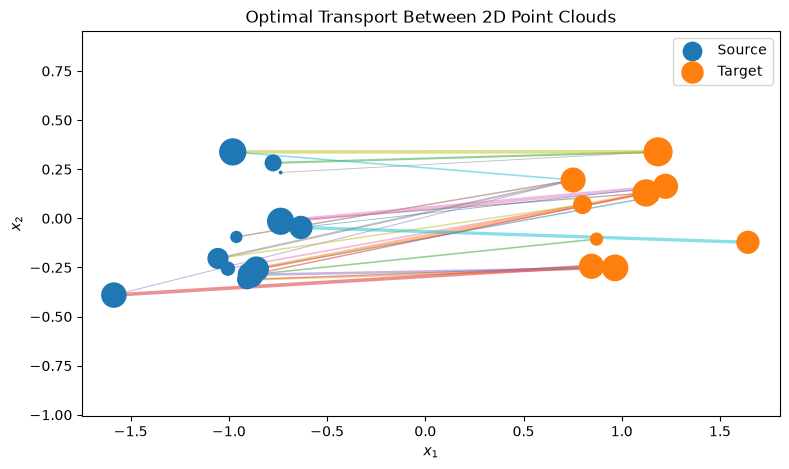

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x[:, 0], x[:, 1], s=2500*a, label="Source", zorder=3)
ax.scatter(y[:, 0], y[:, 1], s=2500*b, label="Target", zorder=3)

for i in range(n):
    for j in range(m):
        if P[i, j] > 1e-9:
            ax.plot([x[i, 0], y[j, 0]], [x[i, 1], y[j, 1]],
                    linewidth=0.6 + 18*P[i, j], alpha=0.5, zorder=1)

ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Optimal Transport Between 2D Point Clouds")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
plt.show()

### 1.1.4 Extreme-point sparsity

For an optimal **extreme point** $P^*$ of the transport polytope, the proof in Task 1.1 gives

$$
|\operatorname{supp}(P^*)|\le n+m-1.
$$

We count entries above a numerical threshold. This is an empirical check of a theorem about extreme points, **not** a claim that every optimal plan must be sparse. Degenerate optima need not be unique, and numerical tolerances can influence the measured support.

In [13]:
tol = 1e-9
nnz = int(np.count_nonzero(P > tol))
bound = n + m - 1
print(f"Number of active transport edges: {nnz}")
print(f"Upper bound n + m - 1: {bound}")
assert nnz <= bound
print("Sparsity bound verified for this HiGHS solution.")

Number of active transport edges: 21
Upper bound n + m - 1: 21
Sparsity bound verified for this HiGHS solution.


### 1.1.5 Uniform weights and the assignment problem

If $n=m$ and $a=b=\frac1n\mathbf1_n$, the Birkhoff–von Neumann theorem guarantees that **some** optimal plan has the form $P^*=\Pi/n$, where $\Pi$ is a permutation matrix. Therefore,

$$
\min_{P\in U(a,b)}\langle C,P\rangle
=\frac1n\min_{\pi\in S_n}\sum_{i=1}^n C_{i,\pi(i)}.
$$

We compare the LP optimal **cost** against the Hungarian/assignment algorithm; different optimal plans can yield the same cost.

In [14]:
n_assign = 8
rng_assign = np.random.default_rng(7)
C_assign = rng_assign.random((n_assign, n_assign))
a_assign = b_assign = np.ones(n_assign) / n_assign
P_assign, lp_assign_cost, _, _ = solve_ot(a_assign, b_assign, C_assign)
row_ind, col_ind = linear_sum_assignment(C_assign)
permutation_cost = C_assign[row_ind, col_ind].sum() / n_assign

print(f"LP optimal cost:         {lp_assign_cost:.12f}")
print(f"Assignment optimal cost: {permutation_cost:.12f}")
print(f"Absolute difference:     {abs(lp_assign_cost-permutation_cost):.3e}")
assert np.isclose(lp_assign_cost, permutation_cost, atol=1e-8)

LP optimal cost:         0.142723695569
Assignment optimal cost: 0.142723695569
Absolute difference:     0.000e+00


## 1.2 — Kantorovich duality and numerical certificates

The dual of the discrete LP is

$$
\begin{aligned}
\max_{f\in\mathbb R^n,\,g\in\mathbb R^m}\quad&a^\top f+b^\top g,\\
\text{subject to}\quad& f_i+g_j\le C_{ij}\quad\forall i,j.
\end{aligned}
$$

For a primal-feasible $P$ and dual-feasible $(f,g)$, weak duality gives a nonnegative gap

$$
\operatorname{Gap}(P,f,g)=\langle C,P\rangle-a^\top f-b^\top g\ge0.
$$

At optimality, strong duality gives zero gap and complementary slackness implies

$$
P^*_{ij}\,(C_{ij}-f_i^*-g_j^*)=0\quad\forall i,j.
$$

SciPy's `eqlin.marginals` supply the dual multipliers associated with the row and column equalities. We check primal and dual feasibility, the objective gap, and the complementary-slackness residual.

In [15]:
slack = C - f[:, None] - g[None, :]
primal_objective = float(np.sum(C * P))
dual_objective = float(a @ f + b @ g)
metrics = {
    "row marginal residual (inf-norm)": np.max(np.abs(P.sum(axis=1) - a)),
    "column marginal residual (inf-norm)": np.max(np.abs(P.sum(axis=0) - b)),
    "primal nonnegativity violation": max(0.0, -float(P.min())),
    "dual feasibility violation": max(0.0, -float(slack.min())),
    "primal-dual gap": primal_objective - dual_objective,
    "complementary slackness residual": np.max(np.abs(P * slack)),
}
for name, value in metrics.items():
    print(f"{name:41s}: {value:.3e}")

assert metrics["row marginal residual (inf-norm)"] < 1e-7
assert metrics["column marginal residual (inf-norm)"] < 1e-7
assert metrics["primal nonnegativity violation"] < 1e-8
assert metrics["dual feasibility violation"] < 1e-7
assert abs(metrics["primal-dual gap"]) < 1e-7
assert metrics["complementary slackness residual"] < 1e-7

row marginal residual (inf-norm)         : 0.000e+00
column marginal residual (inf-norm)      : 3.053e-16
primal nonnegativity violation           : 0.000e+00
dual feasibility violation               : 0.000e+00
primal-dual gap                          : 0.000e+00
complementary slackness residual         : 0.000e+00


### 1.2.1 Independent dual LP (optional validation)

The equality-constraint multipliers returned by HiGHS are convenient, but we can independently solve the dual LP as a second numerical certificate:

$$
\min_{f,g}\; -a^\top f-b^\top g
\quad\text{s.t.}\quad f_i+g_j\le C_{ij}.
$$

Dual variables are unrestricted in sign, and the dual objective is negated to use the minimization interface of `linprog`.

In [16]:
A_dual = sparse.hstack(
    [sparse.kron(sparse.eye(n, format="csr"), np.ones((m, 1)), format="csr"),
     sparse.kron(np.ones((n, 1)), sparse.eye(m, format="csr"), format="csr")],
    format="csr"
)
res_dual = linprog(-np.r_[a, b], A_ub=A_dual, b_ub=C.ravel(),
                   bounds=[(None, None)] * (n + m), method="highs")
assert res_dual.success, res_dual.message
independent_dual_cost = -float(res_dual.fun)
print(f"Primal cost:            {cost:.10f}")
print(f"Independent dual cost:  {independent_dual_cost:.10f}")
print(f"Independent gap:        {cost-independent_dual_cost:.3e}")
assert np.isclose(cost, independent_dual_cost, atol=1e-7)

Primal cost:            4.1854268316
Independent dual cost:  4.1854268316
Independent gap:        0.000e+00


## 1.3 — One-dimensional optimal transport

### 1.3.1 Monotone coupling / quantile matching

Suppose $x_1<\cdots<x_n$, $y_1<\cdots<y_m$, and $c(x,y)=|x-y|^p$ with $p\ge1$. An optimal transport plan exists with **monotone support**: mass is matched in increasing spatial order without crossing transport edges.

This follows from the Monge inequality

$$
c(x_i,y_j)+c(x_k,y_\ell)\le c(x_i,y_\ell)+c(x_k,y_j)
\quad(i<k,\;j<\ell).
$$

The following greedy algorithm processes source and target masses from left to right. It computes the discrete monotone coupling without solving a general LP.

In [17]:
def monotone_coupling_1d(x, a, y, b):
    """Return the 1D monotone transport plan in the ORIGINAL input order."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    a, b = np.asarray(a, float), np.asarray(b, float)
    if x.ndim != 1 or y.ndim != 1 or len(x) != len(a) or len(y) != len(b):
        raise ValueError("Positions and weights must be 1D arrays of matching length")
    if not all(np.isfinite(z).all() for z in (x, y, a, b)):
        raise ValueError("Inputs must be finite")
    if (a < 0).any() or (b < 0).any() or not np.isclose(a.sum(), b.sum(), atol=1e-12):
        raise ValueError("Weights must be nonnegative and have equal total mass")

    sx, sy = np.argsort(x), np.argsort(y)
    aa, bb = a[sx].copy(), b[sy].copy()
    Q = np.zeros((len(a), len(b)), dtype=float)
    i = j = 0
    tol = 1e-13 * max(1.0, float(a.sum()))
    while i < len(aa) and j < len(bb):
        if aa[i] <= tol:
            i += 1
            continue
        if bb[j] <= tol:
            j += 1
            continue
        mass = min(aa[i], bb[j])
        Q[i, j] += mass
        aa[i] -= mass
        bb[j] -= mass

    P_out = np.zeros_like(Q)
    P_out[np.ix_(sx, sy)] = Q
    return P_out


def wasserstein_1d_discrete(x, a, y, b, p=2):
    if p < 1:
        raise ValueError("Require p >= 1")
    P_1d = monotone_coupling_1d(x, a, y, b)
    value = float(np.sum(P_1d * np.abs(np.asarray(x)[:, None] - np.asarray(y)[None, :])**p))
    return P_1d, value ** (1 / p)

### 1.3.2 Compare the monotone method with LP

We compare the quantile-based cost $W_p^p$ with the optimal value of the Kantorovich LP using the cost matrix $C_{ij}=|x_i-y_j|^p$ for $p=1,2,3$. We deliberately supply points in unsorted order to check that the monotone algorithm handles sorting correctly.

For strictly convex costs ($p>1$), crossings cannot be present in an optimal plan when support locations are distinct. For $p=1$, the optimal plan need not be unique, but the monotone plan remains optimal.

In [18]:
x1 = np.array([0.0, -2.0, 1.5, -0.4])
y1 = np.array([2.0, -1.0, 0.5])
a1 = np.array([0.15, 0.25, 0.35, 0.25])
b1 = np.array([0.4, 0.2, 0.4])

P_mon = monotone_coupling_1d(x1, a1, y1, b1)
print("Monotone coupling:\n", np.round(P_mon, 4))
assert np.allclose(P_mon.sum(axis=1), a1)
assert np.allclose(P_mon.sum(axis=0), b1)

for p in (1, 2, 3):
    C1 = np.abs(x1[:, None] - y1[None, :])**p
    _, lp_cost, _, _ = solve_ot(a1, b1, C1)
    _, wp = wasserstein_1d_discrete(x1, a1, y1, b1, p=p)
    print(f"p={p}: LP cost={lp_cost:.10f}, monotone W_p^p={wp**p:.10f}, "
          f"error={abs(lp_cost-wp**p):.2e}")
    assert np.isclose(lp_cost, wp**p, atol=1e-8)

Monotone coupling:
 [[0.05 0.   0.1 ]
 [0.   0.2  0.05]
 [0.35 0.   0.  ]
 [0.   0.   0.25]]
p=1: LP cost=0.8750000000, monotone W_p^p=0.8750000000, error=0.00e+00
p=2: LP cost=1.0275000000, monotone W_p^p=1.0275000000, error=2.22e-16
p=3: LP cost=1.6197500000, monotone W_p^p=1.6197500000, error=6.66e-16


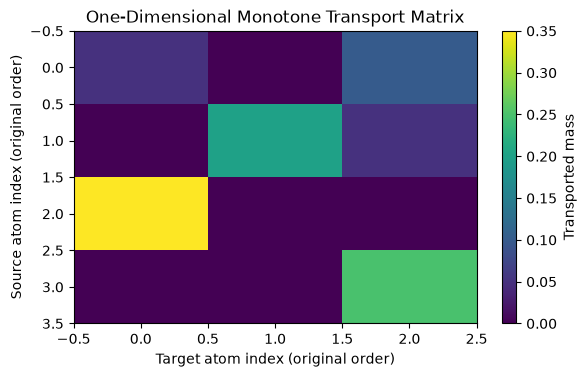

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
im = ax.imshow(P_mon, aspect="auto", interpolation="nearest")
ax.set(xlabel="Target atom index (original order)", ylabel="Source atom index (original order)",
       title="One-Dimensional Monotone Transport Matrix")
fig.colorbar(im, ax=ax, label="Transported mass")
plt.show()

### 1.3.3 Quantile formula and Gaussian benchmark

For probability measures on the real line with finite $p$-th moments,

$$
W_p^p(\mu,\nu)=\int_0^1|F_\mu^{-1}(t)-F_\nu^{-1}(t)|^p\,dt.
$$

For the Gaussian measures $\mu=\mathcal N(m_0,\sigma_0^2)$ and $\nu=\mathcal N(m_1,\sigma_1^2)$, this gives

$$
W_2^2(\mu,\nu)=(m_0-m_1)^2+(\sigma_0-\sigma_1)^2.
$$

Here $\sigma_0,\sigma_1$ are **standard deviations**, not variances. We numerically integrate the squared difference of Gaussian quantile functions and compare with the exact formula.

In [20]:
m0, sigma0 = 0.0, 1.0
m1, sigma1 = 2.0, 3.0

def gaussian_quantile_square(t):
    return (norm.ppf(t, loc=m0, scale=sigma0)
            - norm.ppf(t, loc=m1, scale=sigma1))**2

w2_squared_num, quad_error_est = quad(
    gaussian_quantile_square, 0, 1, epsabs=1e-9, epsrel=1e-9, limit=250
)
w2_squared_exact = (m0-m1)**2 + (sigma0-sigma1)**2
print(f"Numerical W2^2 (quantile integration): {w2_squared_num:.10f}")
print(f"Analytical W2^2 (Gaussian formula):   {w2_squared_exact:.10f}")
print(f"Absolute error:                       {abs(w2_squared_num-w2_squared_exact):.3e}")
print(f"Quadrature error estimate:           {quad_error_est:.3e}")
assert np.isclose(w2_squared_num, w2_squared_exact, atol=1e-7)

Numerical W2^2 (quantile integration): 8.0000000000
Analytical W2^2 (Gaussian formula):   8.0000000000
Absolute error:                       1.306e-12
Quadrature error estimate:           3.691e-10


## 2. Solver scaling and limitations

The project requires handling histograms with up to $n,m\le200$. We benchmark the LP solver on increasing sizes and record runtime, mass-conservation residual, and support size. Results are machine-dependent; a single run is illustrative rather than a robust complexity estimate.

Set `RUN_LARGE_200 = True` to also include a $200\times200$ transport problem (40,000 decision variables). Default execution uses smaller cases for responsiveness.

In [21]:
RUN_LARGE_200 = False
sizes = [20, 50, 100] + ([200] if RUN_LARGE_200 else [])
rng_bench = np.random.default_rng(2026)
bench = []
for size in sizes:
    a_b = rng_bench.random(size); a_b /= a_b.sum()
    b_b = rng_bench.random(size); b_b /= b_b.sum()
    C_b = rng_bench.random((size, size))
    start = perf_counter()
    P_b, value_b, f_b, g_b = solve_ot(a_b, b_b, C_b)
    elapsed = perf_counter() - start
    residual = max(np.max(np.abs(P_b.sum(axis=1)-a_b)),
                   np.max(np.abs(P_b.sum(axis=0)-b_b)))
    nnz_b = int(np.count_nonzero(P_b > 1e-9))
    bench.append((size, elapsed, residual, nnz_b, 2*size-1))
    print(f"n=m={size:3d}: {elapsed:7.3f}s | residual={residual:.2e} "
          f"| support={nnz_b:4d} <= {2*size-1}")
    assert residual < 1e-7
    assert nnz_b <= 2*size-1

n=m= 20:   0.005s | residual=1.67e-16 | support=  39 <= 39
n=m= 50:   0.035s | residual=5.55e-17 | support=  99 <= 99
n=m=100:   0.083s | residual=3.82e-17 | support= 199 <= 199


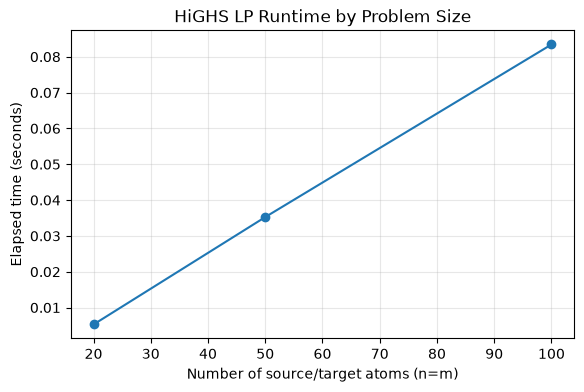

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot([row[0] for row in bench], [row[1] for row in bench], marker="o")
ax.set(xlabel="Number of source/target atoms (n=m)",
       ylabel="Elapsed time (seconds)", title="HiGHS LP Runtime by Problem Size")
ax.grid(alpha=0.3)
plt.show()

### References
- G. Peyré and M. Cuturi, *Computational Optimal Transport*, Foundations and Trends in Machine Learning 11 (2019).
- F. Santambrogio, *Optimal Transport for Applied Mathematicians*, Birkhäuser (2015).
